# 04 – Avaliação em 2025, interpretação e recomendações

Itens 6 (avaliação e interpretação) e 7 (recomendação gerencial) do roteiro, e questão (e) do enunciado.

**Protocolo:** os modelos escolhidos no notebook 03 são ajustados uma única vez com **todos os municípios de 2023** e avaliados **uma única vez** na safra **2025**, que não foi usada em nenhuma escolha anterior (seleção de features, modelo ou hiperparâmetros).

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import spearmanr
from sklearn.inspection import partial_dependence, permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'notebooks'))
import estilo_graficos as eg
import modelagem as md
from estilo_graficos import br

FIGURAS = RAIZ / 'figuras'
PROCESSADOS = RAIZ / 'dados' / 'processados'
eg.aplicar_estilo()
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: br(x, 2))

config = json.loads((PROCESSADOS / 'features.json').read_text(encoding='utf-8'))
escolhidos = json.loads((PROCESSADOS / 'modelos_escolhidos.json').read_text(encoding='utf-8'))
NUMERICAS, ALVO = config['numericas'], config['alvo']
ENTRADAS = NUMERICAS + ['sigla_uf']

# Nomes e microrregiões oficiais (API de localidades do IBGE), só para identificar os municípios
nomes = pd.read_csv(RAIZ / 'dados' / 'brutos' / 'municipios_ibge.csv')[['id_municipio', 'nome_municipio',
                                                                       'microrregiao']]
base = pd.read_csv(PROCESSADOS / 'base_modelagem.csv').merge(nomes, on='id_municipio', how='left')
treino = base[base['ano'] == config['ano_treino']].reset_index(drop=True)
teste = base[base['ano'] == config['ano_teste']].reset_index(drop=True)
X_tr, y_tr = treino[ENTRADAS], treino[ALVO]
X_te, y_te = teste[ENTRADAS], teste[ALVO]
print(f'Treino 2023: {br(len(treino))} municípios | Teste 2025: {br(len(teste))} municípios')
print('Hiperparâmetros do SVR (escolhidos no notebook 03):', escolhidos['svr'])

Treino 2023: 5.241 municípios | Teste 2025: 5.320 municípios
Hiperparâmetros do SVR (escolhidos no notebook 03): {'C': 10, 'epsilon': 0.5, 'gamma': 0.01}


## 1. Ajuste final com todo o treino de 2023

In [2]:
def pipeline(modelo):
    return Pipeline([('prep', md.montar_preprocessador(NUMERICAS, ['sigla_uf'])), ('modelo', modelo)])


modelos = {
    'Baseline: média da UF': md.BaselineMediaUF(),
    'Regressão Linear + UF': pipeline(LinearRegression()),
    'SVR ajustado': pipeline(SVR(kernel='rbf', **escolhidos['svr'])),
}
for modelo in modelos.values():
    modelo.fit(X_tr, y_tr)
previsoes = {nome: modelo.predict(X_te) for nome, modelo in modelos.items()}

## 2. Teste único em 2025

Além das métricas do notebook 03, medimos:
- **Viés**: média de (previsto − real). Negativo indica que o modelo prevê abaixo do que aconteceu.
- **RMSE sem o viés**: o erro que sobra quando se desconta um deslocamento igual para todos os municípios.
- **Spearman entre previsto e real**: se o modelo acerta a **ordem** dos municípios, que é o que importa para priorizar.

In [3]:
cv = pd.read_csv(PROCESSADOS / 'resultados_cv.csv', index_col=0)
NOME_CV = {'Baseline: média da UF': 'Baseline: média da UF',
           'Regressão Linear + UF': 'Regressão Linear + UF',
           'SVR ajustado': 'SVR ajustado (validação aninhada)'}
linhas = []
for nome, prev in previsoes.items():
    erro = prev - y_te
    m = md.metricas(y_te, prev)
    m['RMSE sem o viés'] = erro.std(ddof=0)
    m['R² sem o viés'] = 1 - erro.var(ddof=0) / y_te.var(ddof=0)
    m['Spearman previsto x real'] = spearmanr(prev, y_te).statistic
    m['RMSE na CV 2023'] = cv.loc[NOME_CV[nome], 'RMSE']
    m['R² na CV 2023'] = cv.loc[NOME_CV[nome], 'R²']
    linhas.append(pd.Series(m, name=nome))
teste_2025 = pd.DataFrame(linhas)
teste_2025.to_csv(PROCESSADOS / 'resultados_teste_2025.csv')
teste_2025.style.format(lambda x: br(x, 3))

,RMSE,MAE,R²,Viés (previsto − real),RMSE sem o viés,R² sem o viés,Spearman previsto x real,RMSE na CV 2023,R² na CV 2023
Baseline: média da UF,"0,800","0,598","0,190","-0,395","0,696","0,388","0,643","0,686","0,475"
Regressão Linear + UF,"0,745","0,547","0,298","-0,348","0,658","0,452","0,703","0,642","0,541"
SVR ajustado,"0,711","0,519","0,361","-0,335","0,627","0,503","0,736","0,645","0,537"


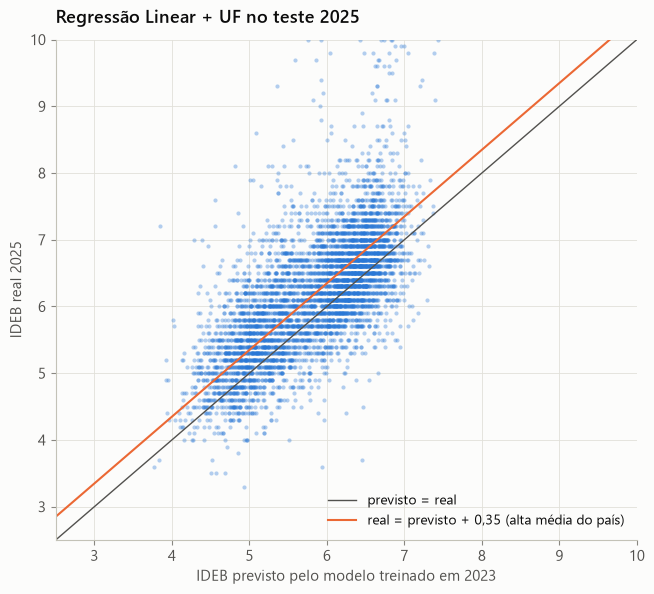

In [4]:
prev_lr = previsoes['Regressão Linear + UF']
deslocamento = float(np.mean(y_te - prev_lr))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.scatter(prev_lr, y_te, s=9, color=eg.AZUL, alpha=0.35, linewidths=0)
lim = np.array([2.5, 10])
ax.plot(lim, lim, color=eg.TINTA_SEC, linewidth=1, label='previsto = real')
ax.plot(lim, lim + deslocamento, color=eg.LARANJA, linewidth=1.5,
        label=f'real = previsto + {br(deslocamento, 2)} (alta média do país)')
ax.legend(loc='lower right')
ax.set_xlim(*lim)
ax.set_ylim(*lim)
ax.set_xlabel('IDEB previsto pelo modelo treinado em 2023')
ax.set_ylabel('IDEB real 2025')
ax.set_title('Regressão Linear + UF no teste 2025')
eg.salvar_figura(fig, '04_previsto_vs_real_2025', FIGURAS)
plt.show()

No teste 2025 todos os modelos erram mais do que na validação cruzada, e a maior parte da piora é **viés**. O IDEB real ficou, em média, 0,35 ponto acima do previsto: o país melhorou entre as edições, e um modelo treinado em 2023 não tem como saber disso. Descontado esse deslocamento (igual para todos os municípios), a Regressão Linear erra 0,658, perto dos 0,642 da validação cruzada, e o SVR erra 0,627. A **ordem** dos municípios se mantém: a correlação de Spearman entre previsto e real é de 0,70 na Regressão Linear e 0,74 no SVR, contra 0,64 do baseline.

**Desafio:** no teste o SVR erra 4,6% menos que a Regressão Linear (RMSE 0,711 contra 0,745), embora os dois tenham empatado na validação cruzada. O SVR parece generalizar melhor para uma edição nova, talvez por captar interações que mudam pouco no tempo. A escolha do modelo principal foi feita antes do teste e não muda por causa dele: trocar agora seria usar o teste para escolher o modelo. Registramos o resultado e, na seção 6.1, verificamos se a escolha muda a lista de prioridades.

### 2.1 Erro por região e por tamanho da rede

In [5]:
# Matrículas dos anos iniciais (não é feature; serve só para medir o tamanho da rede)
matriculas_2025 = (pd.read_csv(RAIZ / 'dados' / 'brutos' / 'base_ideb_municipios.csv',
                               usecols=['ano', 'id_municipio', 'matriculas_ai'])
                   .query('ano == 2025').drop(columns='ano'))
avaliacao = teste[['id_municipio', 'nome_municipio', 'sigla_uf', 'regiao', ALVO]].copy()
avaliacao['previsto'] = prev_lr
avaliacao['erro'] = avaliacao['previsto'] - avaliacao[ALVO]
avaliacao['erro_sem_vies'] = avaliacao['erro'] + deslocamento
avaliacao = avaliacao.merge(matriculas_2025, on='id_municipio', how='left')

por_regiao = avaliacao.groupby('regiao').agg(
    municipios=('erro', 'size'), vies=('erro', 'mean'),
    MAE_sem_vies=('erro_sem_vies', lambda e: e.abs().mean()),
    RMSE_sem_vies=('erro_sem_vies', lambda e: np.sqrt((e ** 2).mean())))
por_regiao.sort_values('MAE_sem_vies')

,municipios,vies,MAE_sem_vies,RMSE_sem_vies
regiao,,,,
Sudeste,1586,"-0,24","0,42","0,54"
Sul,1053,"-0,27","0,45","0,58"
Norte,446,"-0,58","0,47","0,63"
Centro-Oeste,452,"-0,34","0,47","0,61"
Nordeste,1783,"-0,44","0,59","0,80"


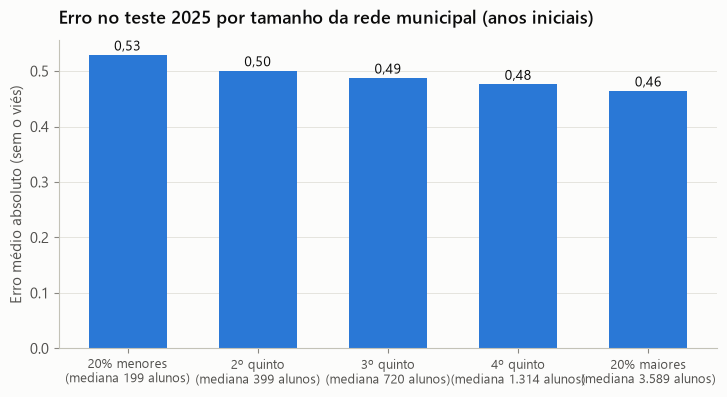

,matriculas_mediana,MAE_sem_vies,pct_erro_acima_1
faixa_rede,,,
20% menores,"199,00","0,53","12,92"
2º quinto,"399,00","0,50","10,45"
3º quinto,"720,50","0,49","9,21"
4º quinto,"1.314,50","0,48","8,93"
20% maiores,"3.589,00","0,46","9,42"


In [6]:
avaliacao['faixa_rede'] = pd.qcut(avaliacao['matriculas_ai'], 5,
                                  labels=['20% menores', '2º quinto', '3º quinto', '4º quinto', '20% maiores'])
por_tamanho = avaliacao.groupby('faixa_rede', observed=True).agg(
    matriculas_mediana=('matriculas_ai', 'median'),
    MAE_sem_vies=('erro_sem_vies', lambda e: e.abs().mean()),
    pct_erro_acima_1=('erro_sem_vies', lambda e: (e.abs() > 1).mean() * 100))

fig, ax = plt.subplots(figsize=(8.5, 4))
xb = np.arange(len(por_tamanho))
ax.bar(xb, por_tamanho['MAE_sem_vies'], color=eg.AZUL, width=0.6)
for i, v in enumerate(por_tamanho['MAE_sem_vies']):
    ax.text(i, v + 0.008, br(v, 2), ha='center', fontsize=10)
ax.set_xticks(xb, [f'{f}\n(mediana {br(m)} alunos)' for f, m in
                   zip(por_tamanho.index, por_tamanho['matriculas_mediana'])], fontsize=9)
ax.set_ylabel('Erro médio absoluto (sem o viés)')
ax.set_title('Erro no teste 2025 por tamanho da rede municipal (anos iniciais)')
ax.grid(axis='x', visible=False)
eg.salvar_figura(fig, '04_erro_por_tamanho_rede', FIGURAS)
plt.show()
por_tamanho

O Norte tem o maior viés (−0,58: foi a região que mais subiu acima do previsto). O Nordeste tem o maior erro depois de descontado o viés (MAE de 0,59, contra 0,42 no Sudeste), como já acontecia na validação cruzada.

A hipótese do notebook 01 sobre redes pequenas se confirma, mas de forma moderada: nas 20% menores redes o erro médio é de 0,53 ponto e 12,9% dos municípios erram mais de 1 ponto, contra 0,46 e 9,4% nas 20% maiores. Em rede pequena, um IDEB baixo numa única edição pode ser oscilação, e não um problema estrutural.

## 3. Interpretação da Regressão Linear

Como as features estão padronizadas, cada coeficiente é a diferença no IDEB esperado associada a **um desvio-padrão a mais** na feature, **mantidas as demais e dentro da mesma UF**. Os intervalos de confiança de 95% usam erros-padrão robustos (HC3), recalculados com `statsmodels` sobre a mesma matriz que o scikit-learn usou.

R² no treino completo: 0,554 | 12 de 24 features com IC 95% que não cruza o zero


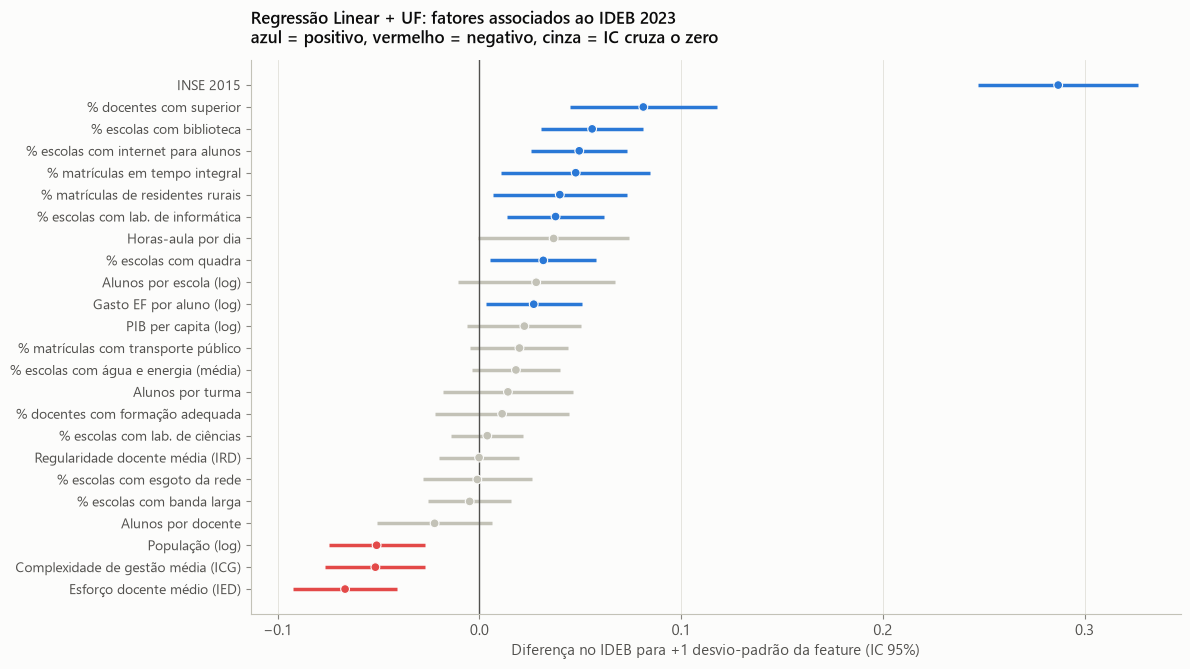

In [7]:
lr = modelos['Regressão Linear + UF']
prep = lr.named_steps['prep']
Z = pd.DataFrame(prep.transform(X_tr), columns=prep.get_feature_names_out())
ols = sm.OLS(y_tr.to_numpy(), sm.add_constant(Z)).fit(cov_type='HC3')
assert np.allclose(ols.params[Z.columns].to_numpy(), lr.named_steps['modelo'].coef_)

ic = ols.conf_int()
coefs = pd.DataFrame({'coef': ols.params, 'ic_inf': ic[0], 'ic_sup': ic[1], 'p': ols.pvalues}).loc[NUMERICAS]
coefs['significativo'] = (coefs['ic_inf'] > 0) | (coefs['ic_sup'] < 0)
coefs = coefs.sort_values('coef')
print(f'R² no treino completo: {br(ols.rsquared, 3)} | {coefs["significativo"].sum()} de {len(coefs)} '
      'features com IC 95% que não cruza o zero')

fig, ax = plt.subplots(figsize=(12, 7.2))
yb = np.arange(len(coefs))
cores = [eg.CINZA if not s else eg.POSITIVO if c > 0 else eg.NEGATIVO
         for c, s in zip(coefs['coef'], coefs['significativo'])]
ax.hlines(yb, coefs['ic_inf'], coefs['ic_sup'], color=cores, linewidth=2.5)
ax.scatter(coefs['coef'], yb, color=cores, s=40, zorder=3, edgecolor=eg.FUNDO, linewidth=0.8)
ax.axvline(0, color=eg.TINTA_SEC, linewidth=1)
ax.set_yticks(yb, [eg.rotulo(c) for c in coefs.index], fontsize=10)
ax.set_xlabel('Diferença no IDEB para +1 desvio-padrão da feature (IC 95%)')
ax.set_title('Regressão Linear + UF: fatores associados ao IDEB 2023\n'
             'azul = positivo, vermelho = negativo, cinza = IC cruza o zero', fontsize=12)
ax.grid(axis='y', visible=False)
eg.salvar_figura(fig, '04_coeficientes_regressao_linear', FIGURAS)
plt.show()

### 3.1 Os coeficientes em unidades do gestor

In [8]:
escala = pd.Series(prep.named_transformers_['num'].named_steps['escala'].scale_, index=NUMERICAS)
VARIACAO = {c: (10, '+10 pontos percentuais') for c in NUMERICAS if c.startswith(('pct_', 'dsu_', 'infra_'))}
VARIACAO.update({
    'inse_medio_2015': (5, '+5 pontos no INSE'),
    'atu_ef_anos_iniciais': (5, '+5 alunos por turma'),
    'alunos_por_docente_ai': (5, '+5 alunos por docente'),
    'had_ef_anos_iniciais': (1, '+1 hora-aula por dia'),
    'ied_medio': (1, '+1 nível de esforço docente'),
    'icg_medio': (1, '+1 nível de complexidade de gestão'),
    'ird_medio': (1, '+1 nível de regularidade docente'),
})
for c in NUMERICAS:
    if c.startswith('log_'):
        VARIACAO[c] = (np.log(2), 'o dobro')

unidades = pd.DataFrame({
    'variação': [VARIACAO[c][1] for c in coefs.index],
    'IDEB associado': [coefs.loc[c, 'coef'] / escala[c] * VARIACAO[c][0] for c in coefs.index],
    'IC 95% inf.': [coefs.loc[c, 'ic_inf'] / escala[c] * VARIACAO[c][0] for c in coefs.index],
    'IC 95% sup.': [coefs.loc[c, 'ic_sup'] / escala[c] * VARIACAO[c][0] for c in coefs.index],
    'IC cruza o zero?': ['não' if s else 'sim' for s in coefs['significativo']],
}, index=[eg.rotulo(c) for c in coefs.index]).iloc[::-1]
unidades

,variação,IDEB associado,IC 95% inf.,IC 95% sup.,IC cruza o zero?
INSE 2015,+5 pontos no INSE,"0,31","0,26","0,35",não
% docentes com superior,+10 pontos percentuais,"0,05","0,03","0,08",não
% escolas com biblioteca,+10 pontos percentuais,"0,02","0,01","0,02",não
% escolas com internet para alunos,+10 pontos percentuais,"0,01","0,01","0,02",não
% matrículas em tempo integral,+10 pontos percentuais,"0,02","0,00","0,03",não
% matrículas de residentes rurais,+10 pontos percentuais,"0,02","0,00","0,03",não
% escolas com lab. de informática,+10 pontos percentuais,"0,01","0,00","0,02",não
Horas-aula por dia,+1 hora-aula por dia,"0,03","-0,00","0,07",sim
% escolas com quadra,+10 pontos percentuais,"0,01","0,00","0,02",não
Alunos por escola (log),o dobro,"0,03","-0,01","0,07",sim


A conversão vale dentro da faixa observada dos dados e supõe as demais variáveis fixas. Um coeficiente com IC que cruza o zero indica que, dado o restante do modelo, não há evidência de associação daquela variável com o IDEB.

### 3.2 O peso da UF

In [9]:
ufs = [c for c in Z.columns if c.startswith('sigla_uf_')]
efeito_uf = pd.concat([pd.Series({'AC': 0.0}), ols.params[ufs].rename(lambda c: c.removeprefix('sigla_uf_'))])
efeito_uf = (efeito_uf - efeito_uf.median()).sort_values()
print('Diferença no IDEB esperado em relação à UF mediana, para municípios de mesmo perfil:')
print(f"Goiás: {br(efeito_uf['GO'], 2)}")
pd.concat([efeito_uf.head(4), efeito_uf.tail(4)]).rename('efeito da UF').to_frame()

Diferença no IDEB esperado em relação à UF mediana, para municípios de mesmo perfil:
Goiás: 0,39


,efeito da UF
AP,"-1,09"
SE,"-0,80"
TO,"-0,73"
RR,"-0,69"
ES,"0,52"
PR,"0,63"
AL,"0,84"
CE,"1,50"


Entre municípios de mesmo perfil, estar no Ceará acompanha um IDEB esperado 1,50 ponto acima da UF mediana, e estar em Alagoas, 0,84 ponto acima. No outro extremo ficam Amapá (−1,09) e Sergipe (−0,80). É o maior "fator" do modelo, e não é municipal: reflete políticas e condições estaduais. Por isso a comparação justa de um município goiano é com outros municípios goianos de perfil parecido, que é o que o modelo faz.

## 4. Importância por permutação (Regressão Linear e SVR)

Embaralhamos uma feature por vez no **conjunto de teste 2025** e medimos quanto o RMSE piora (10 repetições). A UF é embaralhada como uma variável só. Funciona igual para os dois modelos, o que permite comparar o SVR, que não tem coeficientes.

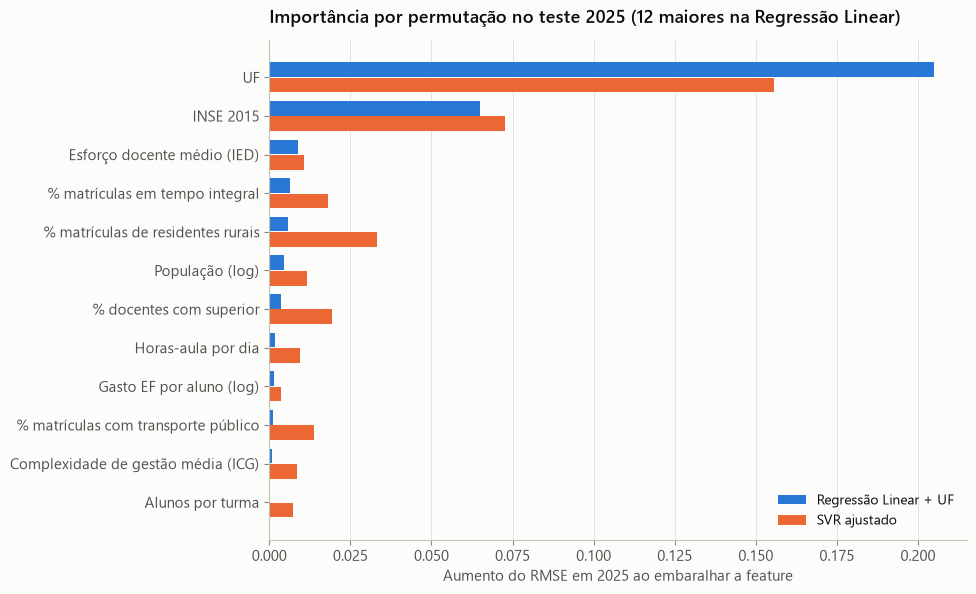

,Regressão Linear + UF,SVR ajustado
UF,"0,2048","0,1555"
INSE 2015,"0,0650","0,0726"
Esforço docente médio (IED),"0,0090","0,0107"
% matrículas em tempo integral,"0,0063","0,0180"
% matrículas de residentes rurais,"0,0058","0,0333"
População (log),"0,0045","0,0117"
% docentes com superior,"0,0037","0,0193"
Horas-aula por dia,"0,0018","0,0095"
Gasto EF por aluno (log),"0,0015","0,0036"
% matrículas com transporte público,"0,0012","0,0137"


In [10]:
importancias = {}
for nome in ['Regressão Linear + UF', 'SVR ajustado']:
    r = permutation_importance(modelos[nome], X_te, y_te, scoring='neg_root_mean_squared_error',
                               n_repeats=10, random_state=42, n_jobs=-1)
    importancias[nome] = pd.Series(r.importances_mean, index=ENTRADAS)
imp = pd.DataFrame(importancias)
imp.index = ['UF' if c == 'sigla_uf' else eg.rotulo(c) for c in imp.index]
top = imp.sort_values('Regressão Linear + UF', ascending=False).head(12)[::-1]

fig, ax = plt.subplots(figsize=(9, 6.5))
yb = np.arange(len(top))
ax.barh(yb + 0.2, top['Regressão Linear + UF'], height=0.38, color=eg.AZUL, label='Regressão Linear + UF')
ax.barh(yb - 0.2, top['SVR ajustado'], height=0.38, color=eg.LARANJA, label='SVR ajustado')
ax.set_yticks(yb, top.index)
ax.set_xlabel('Aumento do RMSE em 2025 ao embaralhar a feature')
ax.set_title('Importância por permutação no teste 2025 (12 maiores na Regressão Linear)')
ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)
eg.salvar_figura(fig, '04_importancia_permutacao', FIGURAS)
plt.show()
imp.sort_values('Regressão Linear + UF', ascending=False).head(12).style.format(lambda x: br(x, 4))

Nos dois modelos a UF é, de longe, a informação mais importante: embaralhá-la aumenta o RMSE em 0,20 ponto na Regressão Linear. Em seguida vem o INSE (0,07). As demais features contribuem pouco individualmente, porque a informação fica dividida entre variáveis correlacionadas. O SVR distribui mais a importância e dá mais peso a % de matrículas rurais, % de docentes com superior e tempo integral, sinal de que aproveita interações entre essas variáveis. O gasto por aluno fica entre as menos importantes nos dois modelos.

## 5. Efeito parcial do gasto por aluno

Quanto muda o IDEB previsto quando só o gasto por aluno varia e todas as outras características de cada município ficam como estão (dependência parcial, calculada no treino 2023, entre os percentis 5% e 95% do gasto).

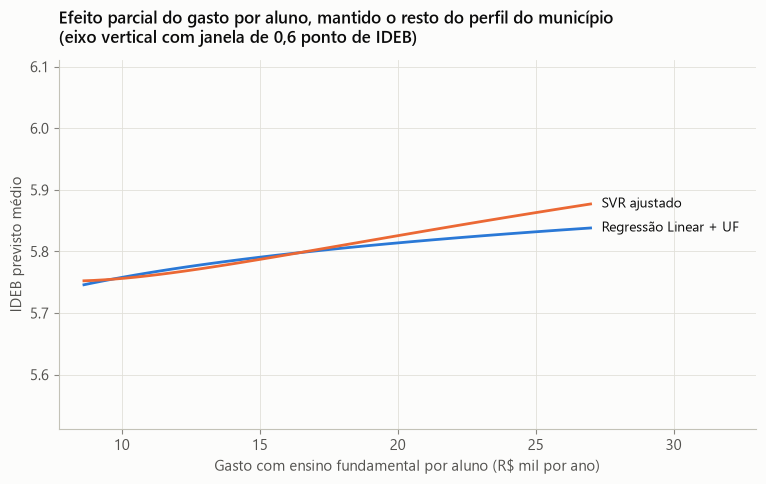

Gasto do percentil 5 ao 95: R$ 8,6 mil -> R$ 26,0 mil
Regressão Linear + UF: IDEB previsto varia 0,09 ponto nessa faixa
SVR ajustado: IDEB previsto varia 0,12 ponto nessa faixa


In [11]:
fig, ax = plt.subplots(figsize=(9, 4.8))
efeitos = {}
for nome, cor in [('Regressão Linear + UF', eg.AZUL), ('SVR ajustado', eg.LARANJA)]:
    pd_res = partial_dependence(modelos[nome], X_tr, ['log_gasto_ef_por_aluno'],
                                grid_resolution=30, percentiles=(0.05, 0.95), kind='average')
    grade_gasto = np.exp(pd_res['grid_values'][0]) / 1000
    media = pd_res['average'][0]
    efeitos[nome] = media[-1] - media[0]
    ax.plot(grade_gasto, media, color=cor, linewidth=2)
    ax.text(grade_gasto[-1] + 0.4, media[-1], nome, va='center', fontsize=10, color=eg.TINTA)
ax.set_xlim(right=grade_gasto[-1] + 6)
centro = np.mean(ax.get_ylim())
ax.set_ylim(centro - 0.3, centro + 0.3)  # janela de 0,6 ponto, para não exagerar a inclinação
ax.set_xlabel('Gasto com ensino fundamental por aluno (R$ mil por ano)')
ax.set_ylabel('IDEB previsto médio')
p5, p95 = np.exp(np.nanpercentile(X_tr['log_gasto_ef_por_aluno'], [5, 95])) / 1000
ax.set_title('Efeito parcial do gasto por aluno, mantido o resto do perfil do município\n'
             '(eixo vertical com janela de 0,6 ponto de IDEB)', fontsize=12)
eg.salvar_figura(fig, '04_efeito_parcial_gasto', FIGURAS)
plt.show()
print(f'Gasto do percentil 5 ao 95: R$ {br(p5, 1)} mil -> R$ {br(p95, 1)} mil')
for nome, v in efeitos.items():
    print(f'{nome}: IDEB previsto varia {br(v, 2)} ponto nessa faixa')

Entre o percentil 5 (R$ 8,6 mil) e o 95 (R$ 26,0 mil) de gasto por aluno, mantido todo o resto, o IDEB previsto sobe só 0,09 ponto na Regressão Linear e 0,12 no SVR. Com o gasto em log, a Regressão Linear já embute retorno decrescente: cada real a mais vale menos. O SVR não mostra saturação nessa faixa. Nos dois casos o efeito parcial é pequeno perto da diferença entre UFs ou do peso do INSE.

Isso **não** quer dizer que dinheiro não importa. Quer dizer que, entre municípios parecidos, gastar mais por aluno, sozinho, não acompanha um IDEB muito diferente. O que provavelmente pesa é **como** o recurso é usado, e isso a base não mede.

## 6. IDEB observado x esperado: quem está acima e quem está abaixo

O IDEB esperado de cada município é a previsão da Regressão Linear + UF. Para 2025, somamos a alta média do país entre as edições (igual para todos), porque o modelo de 2023 não tem como conhecer essa alta. Para 2023, usamos a previsão fora da amostra da validação cruzada (o município é previsto pelo modelo treinado sem ele).

**Regra de priorização:** um município fica **abaixo do esperado** quando o IDEB real está pelo menos **meio ponto** abaixo do esperado **nas duas edições** (2023 e 2025). Meio ponto é próximo do erro médio absoluto do modelo, e exigir as duas edições reduz o risco de reagir a uma oscilação de uma prova só.

In [12]:
LIMIAR = 0.5
CV_2023 = KFold(5, shuffle=True, random_state=42)
prev_oof_2023 = cross_val_predict(pipeline(LinearRegression()), X_tr, y_tr, cv=CV_2023)
d2023 = treino[['id_municipio']].assign(desvio_2023=y_tr - prev_oof_2023)
d2025 = teste[['id_municipio', 'nome_municipio', 'microrregiao', 'sigla_uf', 'regiao', ALVO]].assign(
    esperado_2025=prev_lr + deslocamento)
d2025['desvio_2025'] = d2025[ALVO] - d2025['esperado_2025']
painel = d2025.merge(d2023, on='id_municipio', how='inner')


def classificar(desvio_2023, desvio_2025):
    return np.select([(desvio_2023 <= -LIMIAR) & (desvio_2025 <= -LIMIAR),
                      (desvio_2023 >= LIMIAR) & (desvio_2025 >= LIMIAR)],
                     ['abaixo nas duas edições', 'acima nas duas edições'],
                     default='dentro do esperado ou oscilou')


painel['situacao'] = classificar(painel['desvio_2023'], painel['desvio_2025'])
print(f'Municípios com as duas edições: {br(len(painel))}')
print(f'Correlação entre o desvio de 2023 e o de 2025: {br(painel["desvio_2023"].corr(painel["desvio_2025"]), 2)}')
painel['situacao'].value_counts().to_frame('municípios').assign(
    pct=lambda d: d['municípios'] / d['municípios'].sum() * 100)

Municípios com as duas edições: 5.196
Correlação entre o desvio de 2023 e o de 2025: 0,66


,municípios,pct
situacao,,
dentro do esperado ou oscilou,4097,"78,85"
acima nas duas edições,565,"10,87"
abaixo nas duas edições,534,"10,28"


O desvio de um município em relação ao esperado se repete de uma edição para a outra (correlação de 0,66): quem fica abaixo do esperado em 2023 tende a ficar abaixo em 2025. Logo, o desvio não é só ruído. Ele reflete alguma característica persistente do município que o modelo não mede (gestão, práticas pedagógicas, políticas locais). Pela regra das duas edições, 534 municípios (10,3%) ficam abaixo do esperado e 565 (10,9%) acima.

### 6.1 Robustez: a lista muda se o IDEB esperado vier do SVR?

O SVR errou menos que a Regressão Linear no teste. Se as duas listas de prioridade forem muito diferentes, a escolha do modelo pesa na decisão. Repetimos a classificação com o SVR.

In [13]:
prev_svr = previsoes['SVR ajustado']
oof_svr_2023 = cross_val_predict(pipeline(SVR(kernel='rbf', **escolhidos['svr'])), X_tr, y_tr,
                                 cv=CV_2023, n_jobs=-1)
alternativo = (teste[['id_municipio']].assign(desvio_2025_svr=y_te - (prev_svr + np.mean(y_te - prev_svr)))
               .merge(treino[['id_municipio']].assign(desvio_2023_svr=y_tr - oof_svr_2023), on='id_municipio'))
painel = painel.merge(alternativo, on='id_municipio', how='left')
painel['situacao_svr'] = classificar(painel['desvio_2023_svr'], painel['desvio_2025_svr'])

concordancia = pd.crosstab(painel['situacao'], painel['situacao_svr'], margins=True,
                           rownames=['Regressão Linear'], colnames=['SVR'])
abaixo_lr = painel['situacao'] == 'abaixo nas duas edições'
abaixo_svr = painel['situacao_svr'] == 'abaixo nas duas edições'
print(f'Concordância geral: {br((painel["situacao"] == painel["situacao_svr"]).mean() * 100, 1)}%')
print(f'Dos {abaixo_lr.sum()} municípios abaixo do esperado pela Regressão Linear, '
      f'{(abaixo_lr & abaixo_svr).sum()} ({(abaixo_lr & abaixo_svr).sum() / abaixo_lr.sum() * 100:.0f}%) '
      'também estão abaixo pelo SVR')
painel['svr_concorda'] = painel['situacao'] == painel['situacao_svr']
concordancia

Concordância geral: 88,9%
Dos 534 municípios abaixo do esperado pela Regressão Linear, 300 (56%) também estão abaixo pelo SVR


SVR,abaixo nas duas edições,acima nas duas edições,dentro do esperado ou oscilou,All
Regressão Linear,,,,
abaixo nas duas edições,300,0,234,534
acima nas duas edições,0,405,160,565
dentro do esperado ou oscilou,107,77,3913,4097
All,407,482,4307,5196


As duas classificações concordam em 88,9% dos municípios, mas só 300 dos 534 municípios abaixo do esperado pela Regressão Linear (56%) também ficam abaixo pelo SVR. As divergências são de fronteira (um modelo põe o município abaixo, o outro o põe dentro do esperado): nenhum município passa de "abaixo" para "acima".

**Ajuste na recomendação:** a lista principal de prioridade são os **300 municípios em que os dois modelos concordam**. Os demais ficam numa segunda faixa, para acompanhamento.

## 7. Estudo de caso: Goiás

In [14]:
go = painel[painel['sigla_uf'] == 'GO'].merge(
    teste[['id_municipio', 'inse_medio_2015', 'log_gasto_ef_por_aluno', 'pct_formacao_adequada',
           'dsu_ef_anos_iniciais', 'pct_esc_biblioteca', 'pct_esc_quadra', 'pct_matr_integral_ai',
           'atu_ef_anos_iniciais', 'log_populacao']], on='id_municipio')
go['gasto_por_aluno'] = np.exp(go['log_gasto_ef_por_aluno'])
go['populacao'] = np.exp(go['log_populacao']).round()
print(f'Goiás: {len(go)} municípios com IDEB nas duas edições')
go['situacao'].value_counts().to_frame('municípios')

Goiás: 237 municípios com IDEB nas duas edições


,municípios
situacao,
dentro do esperado ou oscilou,179
abaixo nas duas edições,30
acima nas duas edições,28


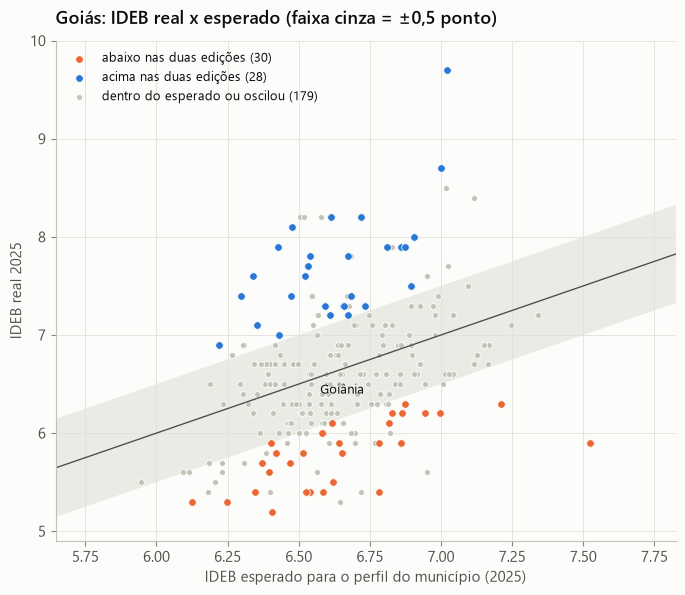

In [15]:
CORES_SITUACAO = {'abaixo nas duas edições': eg.LARANJA, 'acima nas duas edições': eg.AZUL,
                  'dentro do esperado ou oscilou': eg.CINZA}
fig, ax = plt.subplots(figsize=(8, 6.5))
for situacao, cor in CORES_SITUACAO.items():
    parte = go[go['situacao'] == situacao]
    ax.scatter(parte['esperado_2025'], parte[ALVO], s=30 if cor != eg.CINZA else 18, color=cor,
               edgecolor=eg.FUNDO, linewidth=0.6, label=f'{situacao} ({len(parte)})',
               zorder=3 if cor != eg.CINZA else 2)
lim = np.array([4.5, 10])
ax.plot(lim, lim, color=eg.TINTA_SEC, linewidth=1)
ax.fill_between(lim, lim - LIMIAR, lim + LIMIAR, color=eg.CINZA_CLARO, alpha=0.6, linewidth=0)
goiania = go[go['id_municipio'] == 5208707].iloc[0]
ax.annotate('Goiânia', (goiania['esperado_2025'], goiania[ALVO]), xytext=(8, -14),
            textcoords='offset points', fontsize=9, color=eg.TINTA)
ax.set_xlim(go['esperado_2025'].min() - 0.3, go['esperado_2025'].max() + 0.3)
ax.set_ylim(go[ALVO].min() - 0.3, go[ALVO].max() + 0.3)
ax.set_xlabel('IDEB esperado para o perfil do município (2025)')
ax.set_ylabel('IDEB real 2025')
ax.set_title('Goiás: IDEB real x esperado (faixa cinza = ±0,5 ponto)')
ax.legend(loc='upper left', fontsize=9)
eg.salvar_figura(fig, '04_goias_real_vs_esperado', FIGURAS)
plt.show()

In [16]:
COLS_TAB = ['nome_municipio', 'microrregiao', 'populacao', ALVO, 'esperado_2025', 'desvio_2025',
            'desvio_2023', 'svr_concorda', 'gasto_por_aluno', 'pct_formacao_adequada',
            'pct_esc_biblioteca']
NOMES_TAB = {'nome_municipio': 'município', 'microrregiao': 'microrregião', 'populacao': 'população',
             ALVO: 'IDEB 2025', 'esperado_2025': 'esperado 2025', 'desvio_2025': 'desvio 2025',
             'desvio_2023': 'desvio 2023', 'svr_concorda': 'SVR concorda?',
             'gasto_por_aluno': 'gasto/aluno (R$)', 'pct_formacao_adequada': '% formação adequada',
             'pct_esc_biblioteca': '% escolas c/ biblioteca'}


def formatar_tabela(df):
    """Números no padrão brasileiro para exibição."""
    saida = df.rename(columns=NOMES_TAB).copy()
    for col in saida.columns:
        if col in ('população', 'gasto/aluno (R$)'):
            saida[col] = saida[col].map(lambda v: br(v))
        elif col == 'IDEB 2025':
            saida[col] = saida[col].map(lambda v: br(v, 1))
        elif col == 'SVR concorda?':
            saida[col] = saida[col].map({True: 'sim', False: 'não'})
        elif saida[col].dtype.kind == 'f':
            saida[col] = saida[col].map(lambda v: br(v, 2))
    saida.index = range(1, len(saida) + 1)
    return saida


abaixo_go = go[go['situacao'] == 'abaixo nas duas edições'].sort_values('desvio_2025')[COLS_TAB]
print(f'Goiás – {len(abaixo_go)} municípios abaixo do esperado nas duas edições (prioridade de diagnóstico); '
      f'{abaixo_go["svr_concorda"].sum()} também pelo SVR:')
formatar_tabela(abaixo_go)

Goiás – 30 municípios abaixo do esperado nas duas edições (prioridade de diagnóstico); 19 também pelo SVR:


,município,microrregião,população,IDEB 2025,esperado 2025,desvio 2025,desvio 2023,SVR concorda?,gasto/aluno (R$),% formação adequada,% escolas c/ biblioteca
1,Goiandira,Catalão,4.962,"5,9","7,52","-1,62","-1,69",sim,26.917,"50,00","100,00"
2,Caturaí,Anápolis,5.352,"5,4","6,78","-1,38","-0,83",sim,19.562,"94,30","100,00"
3,Santo Antônio do Descoberto,Entorno de Brasília,75.221,"5,2","6,41","-1,21","-1,34",sim,8.316,"95,30","82,35"
4,Guarani de Goiás,Vão do Paranã,4.091,"5,4","6,59","-1,19","-1,38",sim,24.452,"85,60","60,00"
5,Divinópolis de Goiás,Vão do Paranã,4.405,"5,4","6,54","-1,14","-1,03",sim,17.598,"49,50","75,00"
6,Monte Alegre de Goiás,Chapada dos Veadeiros,6.534,"5,4","6,53","-1,13","-1,41",sim,20.589,"82,40","18,18"
7,Mimoso de Goiás,Entorno de Brasília,2.626,"5,5","6,62","-1,12","-0,60",não,51.164,"64,80","50,00"
8,Campo Alegre de Goiás,Catalão,7.807,"5,9","6,86","-0,96","-0,58",não,30.766,"52,00","100,00"
9,Hidrolândia,Goiânia,30.587,"5,4","6,35","-0,95","-0,83",sim,16.942,"79,30","66,67"
10,Novo Gama,Entorno de Brasília,107.663,"5,3","6,25","-0,95","-0,58",sim,13.098,"94,60","35,71"


In [17]:
por_micro = (go.groupby('microrregiao')['situacao'].value_counts().unstack(fill_value=0)
             .assign(municipios=lambda d: d.sum(axis=1))
             .sort_values('abaixo nas duas edições', ascending=False))
por_micro = por_micro[['municipios', 'abaixo nas duas edições', 'acima nas duas edições']]
print('Goiás – microrregiões com mais municípios abaixo do esperado:')
por_micro.head(6)

Goiás – microrregiões com mais municípios abaixo do esperado:


situacao,municipios,abaixo nas duas edições,acima nas duas edições
microrregiao,,,
Entorno de Brasília,20,7,1
Goiânia,17,3,2
Vão do Paranã,12,3,0
Rio Vermelho,9,3,1
Pires do Rio,9,2,0
Porangatu,19,2,2


In [18]:
acima_go = (go[go['situacao'] == 'acima nas duas edições']
            .sort_values('desvio_2025', ascending=False)[COLS_TAB].head(10))
print('Goiás – 10 municípios mais acima do esperado nas duas edições (referências para estudar):')
formatar_tabela(acima_go)

Goiás – 10 municípios mais acima do esperado nas duas edições (referências para estudar):


,município,microrregião,população,IDEB 2025,esperado 2025,desvio 2025,desvio 2023,SVR concorda?,gasto/aluno (R$),% formação adequada,% escolas c/ biblioteca
1,Mossâmedes,Anicuns,4.626,"9,7","7,02","2,68","0,53",sim,24.691,"78,90","100,00"
2,Buriti de Goiás,Anicuns,2.800,"8,7","7,00","1,70","0,80",sim,28.181,"89,30","100,00"
3,Rio Verde,Sudoeste de Goiás,241.494,"8,1","6,48","1,62","1,62",sim,18.327,"85,20","59,52"
4,Goianésia,Ceres,78.009,"8,2","6,61","1,59","1,09",sim,10.079,"85,70","92,86"
5,Santa Rita do Novo Destino,Ceres,2.611,"8,2","6,72","1,48","1,70",sim,45.859,"78,10","66,67"
6,Santo Antônio de Goiás,Goiânia,8.066,"7,9","6,43","1,47","0,91",sim,24.649,"90,70","100,00"
7,Nova Iguaçu de Goiás,Porangatu,3.084,"7,8","6,54","1,26","0,68",sim,32.888,"86,70","100,00"
8,Maurilândia,Sudoeste de Goiás,10.145,"7,6","6,34","1,26","1,30",sim,22.992,"82,00","100,00"
9,Jesúpolis,Anápolis,2.112,"7,7","6,53","1,17","1,78",sim,25.784,"100,00","100,00"
10,Anicuns,Anicuns,18.306,"7,8","6,67","1,13","1,00",sim,21.120,"84,60","66,67"


In [19]:
ALAVANCAS = {'inse_medio_2015': 'INSE 2015', 'gasto_por_aluno': 'Gasto por aluno (R$)',
             'pct_formacao_adequada': '% docentes com formação adequada',
             'dsu_ef_anos_iniciais': '% docentes com superior', 'pct_esc_biblioteca': '% escolas com biblioteca',
             'pct_esc_quadra': '% escolas com quadra', 'pct_matr_integral_ai': '% matrículas em tempo integral',
             'atu_ef_anos_iniciais': 'Alunos por turma', 'populacao': 'População'}
perfis = go.groupby('situacao')[list(ALAVANCAS)].median().T.rename(index=ALAVANCAS)
perfis = perfis[['abaixo nas duas edições', 'dentro do esperado ou oscilou', 'acima nas duas edições']]
print('Medianas por grupo em Goiás (2025):')
perfis

Medianas por grupo em Goiás (2025):


situacao,abaixo nas duas edições,dentro do esperado ou oscilou,acima nas duas edições
INSE 2015,"49,83","50,10","49,86"
Gasto por aluno (R$),"22.841,09","21.339,86","23.820,40"
% docentes com formação adequada,"81,15","79,30","84,90"
% docentes com superior,"95,95","96,60","97,60"
% escolas com biblioteca,"93,52","100,00","96,43"
% escolas com quadra,"50,00","50,00","66,67"
% matrículas em tempo integral,"1,38","7,58","1,44"
Alunos por turma,"20,15","20,40","20,15"
População,"4.683,50","8.493,00","5.820,00"


In [20]:
print('Goiânia:')
formatar_tabela(go.loc[go['id_municipio'] == 5208707, COLS_TAB + ['situacao']])

Goiânia:


,município,microrregião,população,IDEB 2025,esperado 2025,desvio 2025,desvio 2023,SVR concorda?,gasto/aluno (R$),% formação adequada,% escolas c/ biblioteca,situacao
1,Goiânia,Goiânia,1.503.256,"6,6","6,54","0,06","0,32",sim,17.086,"90,50","78,31",dentro do esperado ou oscilou


- Dos 237 municípios goianos com IDEB nas duas edições, **30 ficam abaixo do esperado nas duas**, e o SVR concorda em 19 deles. Outros 28 ficam acima nas duas edições.
- **Padrão geográfico:** 7 dos 30 estão na microrregião do **Entorno de Brasília** (Santo Antônio do Descoberto, Novo Gama, Cidade Ocidental, Planaltina, Cristalina, Mimoso de Goiás e Vila Boa) e 3 na microrregião de **Goiânia** (Senador Canedo, Hidrolândia e Bela Vista de Goiás). Os maiores (Senador Canedo, Planaltina, Novo Gama, Cidade Ocidental e Santo Antônio do Descoberto, todos acima de 75 mil habitantes) são cidades de periferia metropolitana. A pressão do crescimento populacional sobre a rede é uma hipótese a investigar.
- Os municípios abaixo do esperado **não gastam menos**: a mediana de gasto por aluno é parecida nos três grupos (R$ 22,8 mil abaixo, R$ 21,3 mil dentro e R$ 23,8 mil acima do esperado). O INSE também é igual (49,8 contra 49,9). As diferenças aparecem em % de docentes com formação adequada (81% contra 85%) e em % de escolas com quadra (50% contra 67%), e mesmo essas são pequenas. A maior parte do que separa os dois grupos não está na base, o que reforça o diagnóstico em campo como próximo passo.
- Goiânia fica dentro do esperado nas duas edições (+0,32 ponto em 2023 e +0,06 em 2025).
- Referências para estudar: Rio Verde (241 mil habitantes) e Goianésia (78 mil) ficam mais de 1 ponto acima do esperado nas duas edições, com gasto por aluno abaixo da mediana do estado. Goianésia gasta R$ 10,1 mil por aluno.

## 8. Associação não é causalidade (questão e)

O modelo mostra **quais características acompanham** um IDEB mais alto entre municípios parecidos. Ele não mostra o que **aconteceria** com o IDEB se uma dessas características mudasse. Três razões, todas visíveis nos nossos dados:

1. **Confusão.** Municípios que gastam mais por aluno também têm, em média, famílias de nível socioeconômico mais alto (notebook 01, seção 6.1). Sem controles, dobrar o gasto acompanha +0,41 ponto; com INSE, PIB e UF, +0,11. Mesmo esse valor menor pode ainda carregar fatores que não medimos (qualidade da gestão, participação das famílias).
2. **Causalidade reversa.** Uma rede com bons resultados pode atrair professores mais qualificados ou conseguir mais recursos, e não o contrário.
3. **Variáveis omitidas.** O efeito do Ceará mostra que políticas estaduais pesam muito e não aparecem em nenhuma variável municipal. O mesmo vale para práticas de gestão escolar, que a base não mede.

**Como usar então:** o modelo serve para **priorizar e investigar** (quem está abaixo do esperado para o seu perfil e em que características difere dos que estão acima). Para saber se um investimento funciona, é preciso avaliá-lo: implantar em parte dos municípios priorizados, acompanhar um grupo de comparação parecido e medir a diferença nas edições seguintes do IDEB.

## 9. Recomendações para a gestão pública

1. **Usar o IDEB esperado como régua, e não a média nacional.** Cada município é comparado com municípios de perfil parecido no mesmo estado, o que evita cobrar o mesmo resultado de redes com contextos muito diferentes. O esperado deve ser apresentado como faixa (± 0,5 ponto), nunca como meta exata.
2. **Priorizar o diagnóstico nos municípios abaixo do esperado nas duas edições, começando pelos que os dois modelos apontam** (300 no país, 19 em Goiás). O passo seguinte não é transferir recurso automaticamente: é uma visita técnica para entender gestão escolar, formação e lotação dos professores, uso do tempo e acompanhamento da alfabetização.
3. **Aprender com quem está acima do esperado.** Os 565 municípios acima do esperado nas duas edições (28 em Goiás, como Rio Verde e Goianésia) são candidatos a troca de experiências. O caso do Ceará mostra que uma política estadual de colaboração na alfabetização acompanha resultados bem acima do esperado.
4. **Olhar a qualidade do gasto antes da quantidade.** Entre municípios parecidos, dobrar o gasto por aluno acompanha só +0,06 ponto de IDEB (IC 95% de 0,01 a 0,11). Antes de ampliar o orçamento de um município abaixo do esperado, verificar como o recurso está sendo aplicado.
5. **Alavancas controláveis com associação positiva:** % de docentes com ensino superior (+0,05 ponto a cada 10 p.p.), escolas com biblioteca, internet para alunos e laboratório de informática, e matrículas em tempo integral. Esforço docente alto (professores com muitas turmas, turnos e escolas) e escolas de gestão complexa acompanham IDEB menor. São hipóteses para programas-piloto **avaliados**, não garantia de efeito.
6. **Goiás – ação regional no Entorno de Brasília.** Sete dos 30 municípios goianos priorizados ficam nessa microrregião. Uma ação conjunta com o estado tende a ser mais eficiente que sete diagnósticos isolados.
7. **Atualizar o modelo a cada edição do IDEB** e acompanhar o erro por região e por tamanho de rede. Substituir o INSE de 2015 e os indicadores de 2022 assim que houver dados novos.

## 10. Riscos e limitações

| Limitação | Efeito na análise | Como mitigar |
|---|---|---|
| Associação não é causalidade | Os coeficientes não medem o efeito de investir | Usar para priorizar; avaliar intervenções com grupo de comparação |
| INSE de 2015 | Nível socioeconômico defasado em 8 a 10 anos | Substituir pelo INSE mais recente quando publicado na base |
| Indicadores educacionais de 2022 nas duas safras | Defasagem de 3 anos no teste 2025 | Baixar os arquivos oficiais do INEP de 2023 e 2024 |
| Gasto autodeclarado no Siconfi | Erros de valor e classificação; 4,2% sem gasto em 2025 | Regra de plausibilidade e conferência com o SIOPE |
| Redes pequenas | IDEB mais instável entre edições | Exigir duas edições antes de classificar um município |
| Municípios sem IDEB (5,9%) | Viés de seleção: o modelo não vale para eles | Acompanhar por outros indicadores (fluxo, avaliações estaduais) |
| Alta média de 2023 para 2025 | O modelo subestima o nível em edições novas | Recalibrar a cada edição; usar a posição relativa para priorizar |
| R² em torno de 0,5 | Metade da variação entre municípios fica sem explicação | Apresentar o esperado como faixa (± erro típico), nunca como meta exata |